# Project Questions

1. **Q1:** How does renewable-energy adoption differ across the 10 selected countries? Visuals 1 and 6.
2. **Q2:** How do countries differ in the renewable sources they rely on, especially solar, wind, and hydropower? Visuals 2, 7, and 5.
3. **Q3:** What patterns appear when we compare renewable-energy adoption with economic context and change over time? Visuals 3, 4, 8, and 9; Visual 5 also shows change over time.

**Final synthesis:** Visual 5, the animated 3D geographic renewable-energy map. Each visual uses its stated year or range; different measures have different latest available years.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/energy_10countries_clean.csv").is_file())
data = pd.read_csv(root / "data/energy_10countries_clean.csv")
countries = ["Germany", "Denmark", "Norway", "France", "China",
             "United States", "India", "Brazil", "Japan", "South Africa"]
data = data.loc[data.country.isin(countries)].copy()
assert data.groupby("year").country.nunique().max() == len(countries)
assert not data.duplicated(["country", "year"]).any()

source_cols = ["hydro_share_elec", "wind_share_elec", "solar_share_elec"]
source_colors = ["#0072B2", "#009E73", "#E69F00"]
country_colors = dict(zip(countries, ["#4E79A7", "#59A14F", "#76B7B2", "#F28E2B",
                                        "#E15759", "#B07AA1", "#EDC948", "#2F9D8F",
                                        "#9C755F", "#7F8C8D"]))

## Question 1

**How does renewable-energy adoption differ across the 10 selected countries?**

### Visual 1 — Renewable adoption in 2024

![Visual 1: renewable adoption in 2024](../visuals/01_renewable_adoption_2024.png)

### Visual 6 — Electricity versus primary energy

The two percentages use different denominators. The latest year with both measures for all ten countries is selected below.

In [2]:
measures = ["renewables_share_energy", "renewables_share_elec"]
valid = data.dropna(subset=measures)
v6_year = int(valid.groupby("year").country.nunique().loc[lambda s: s.eq(len(countries))].index.max())
v6 = valid.loc[valid.year.eq(v6_year), ["country", *measures]].copy()
v6["gap_pp"] = v6.renewables_share_elec - v6.renewables_share_energy
v6 = v6.sort_values("gap_pp", ascending=False).reset_index(drop=True)
print(f"Visual 6 common year: {v6_year}; largest gaps:")
display(v6[["country", "gap_pp"]].head(3).round(1))

Visual 6 common year: 2024; largest gaps:


,country,gap_pp
0,Denmark,47.5
1,Brazil,37.7
2,Germany,34.7


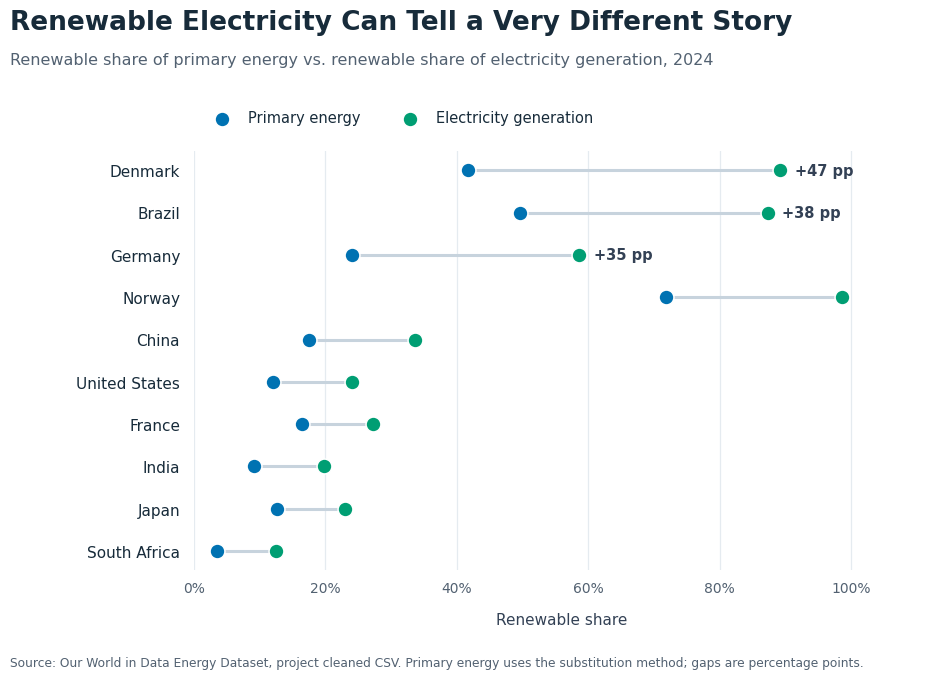

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 7.1), facecolor="white")
fig.subplots_adjust(left=0.23, right=0.87, top=0.76, bottom=0.17)
y = range(len(v6))
ax.hlines(y, v6.renewables_share_energy, v6.renewables_share_elec,
          color="#C7D3DD", linewidth=2.2, zorder=1)
ax.scatter(v6.renewables_share_energy, y, s=115, color=source_colors[0],
           edgecolor="white", linewidth=1.1, label="Primary energy", zorder=3)
ax.scatter(v6.renewables_share_elec, y, s=115, color=source_colors[1],
           edgecolor="white", linewidth=1.1, label="Electricity generation", zorder=3)
for row in v6.head(3).itertuples():
    ax.text(row.renewables_share_elec + 2.2, row.Index, f"+{row.gap_pp:.0f} pp",
            va="center", fontsize=10.5, fontweight="bold", color="#334155")
ax.set_yticks(list(y), v6.country, fontsize=11, color="#172B3A")
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.tick_params(axis="x", labelsize=10, colors="#526171", length=0, pad=8)
ax.tick_params(axis="y", length=0, pad=10)
ax.grid(axis="x", color="#E5EBF0", linewidth=0.9)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.07, 0.96, "Renewable Electricity Can Tell a Very Different Story",
         fontsize=19, fontweight="bold", color="#172B3A", va="top")
fig.text(0.07, 0.90,
         f"Renewable share of primary energy vs. renewable share of electricity generation, {v6_year}",
         fontsize=11.5, color="#526171", va="top")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.03), ncol=2,
          frameon=False, fontsize=10.5, labelcolor="#172B3A", columnspacing=2.4)
ax.set_xlabel("Renewable share", fontsize=11, color="#334155", labelpad=12)
fig.text(0.07, 0.035,
         "Source: Our World in Data Energy Dataset, project cleaned CSV. "
         "Primary energy uses the substitution method; gaps are percentage points.",
         fontsize=8.8, color="#526171")
fig.savefig(root / "visuals/06_electricity_vs_total_energy.png", dpi=300, facecolor="white")
plt.show()

**Q1 takeaway.** In 2024, Denmark (47.5 percentage points), Brazil (37.7), and Germany (34.7) had the largest electricity-minus-primary gaps. Electricity is only one part of primary energy, so its renewable share should not be read as the share for all energy uses. These gaps describe differences, not their causes.

## Question 2

**How do countries differ in the renewable sources they rely on, especially solar, wind, and hydropower?**

### Visual 2 — Renewable electricity pathways in 2024

![Visual 2: renewable electricity pathways in 2024](../visuals/02_renewable_electricity_pathways_2024.png)

### Visual 7 — Renewable source mix over time

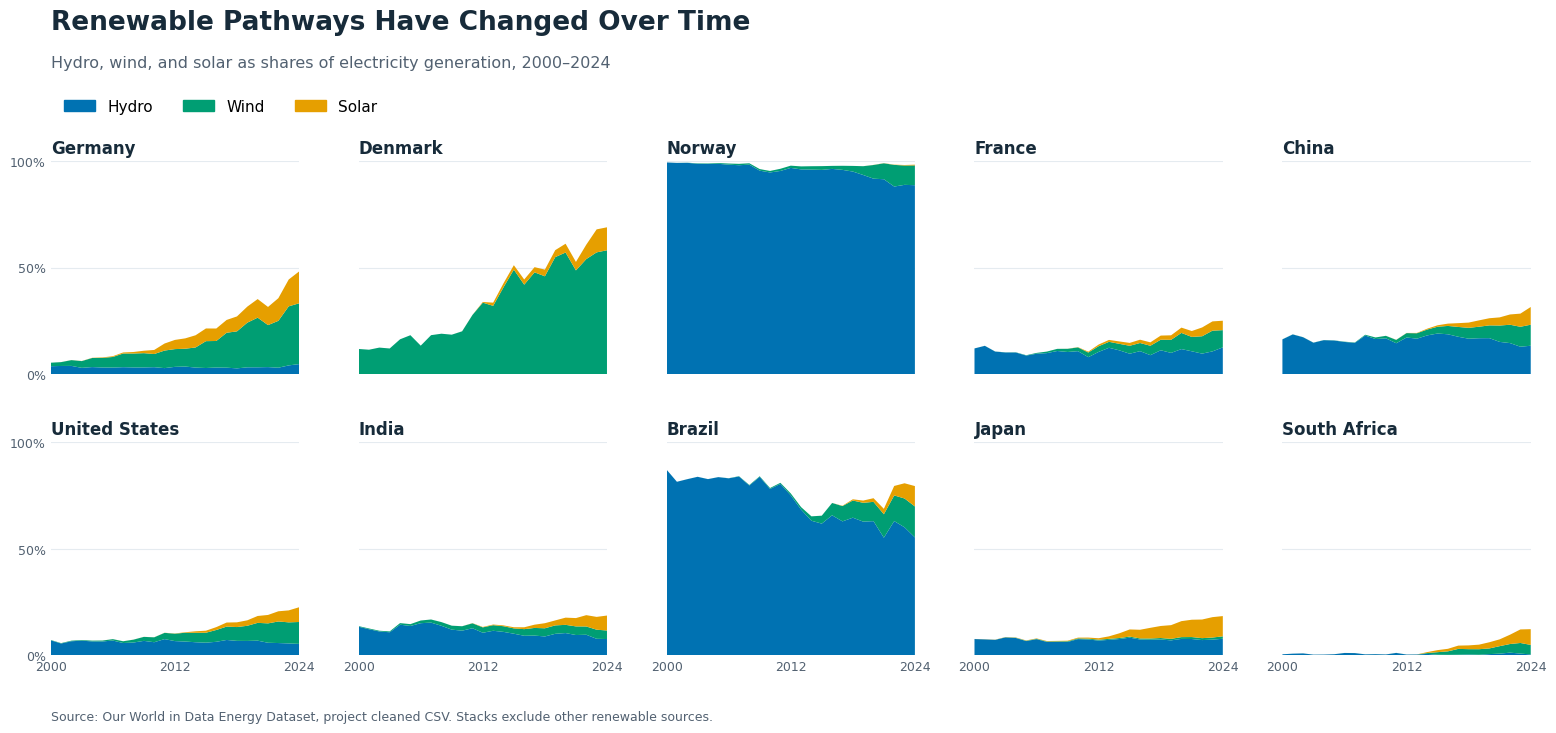

In [4]:
v7 = data.loc[data.year.between(2000, 2024)].dropna(subset=source_cols)
assert v7.groupby("country").year.nunique().eq(25).all(), "A country-year is missing."
fig, axes = plt.subplots(2, 5, figsize=(16, 7.6), sharex=True, sharey=True, facecolor="white")
for ax, country in zip(axes.flat, countries):
    part = v7.loc[v7.country.eq(country)].sort_values("year")
    ax.stackplot(part.year, *[part[col] for col in source_cols], colors=source_colors)
    ax.set_title(country, loc="left", fontsize=12, fontweight="bold", color="#172B3A")
    ax.set_xlim(2000, 2024)
    ax.set_ylim(0, 100)
    ax.set_xticks([2000, 2012, 2024])
    ax.set_yticks([0, 50, 100], ["0%", "50%", "100%"])
    ax.grid(axis="y", color="#E5EBF0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=9, colors="#526171")
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.subplots_adjust(left=0.055, right=0.98, top=0.77, bottom=0.12, wspace=0.24, hspace=0.32)
fig.text(0.055, 0.97, "Renewable Pathways Have Changed Over Time",
         fontsize=19, fontweight="bold", color="#172B3A", va="top")
fig.text(0.055, 0.91, "Hydro, wind, and solar as shares of electricity generation, 2000–2024",
         fontsize=11.5, color="#526171", va="top")
fig.legend([Patch(color=c) for c in source_colors], ["Hydro", "Wind", "Solar"],
           loc="upper left", bbox_to_anchor=(0.055, 0.87), ncol=3, frameon=False, fontsize=11)
fig.text(0.055, 0.035,
         "Source: Our World in Data Energy Dataset, project cleaned CSV. Stacks exclude other renewable sources.",
         fontsize=9, color="#526171")
fig.savefig(root / "visuals/07_source_mix_over_time.png", dpi=250, facecolor="white")
plt.show()

**Q2 takeaway.** Norway and Brazil were already hydro-heavy in 2000. Wind grew strongly in Denmark and Germany, while solar became more visible later in countries such as China and Japan. The stacks show shares of *all electricity generation*; they do not include other renewable sources.

### Visual 5 — Geographic synthesis of renewable pathways

[Open the animated 3D map](../visuals/05_3d_renewable_energy_map.html) (2000–2024). Its blue, green, and orange column segments place the changing mix on a world map.

## Question 3

**What patterns appear when we compare renewable-energy adoption with economic context and change over time?**

### Visual 3 — Economic context (2022)

![Visual 3: GDP per capita versus renewable share](../visuals/03_gdp_vs_renewables.png)

### Visual 4 — Change over time (2000–2024)

![Visual 4: transition over time](../visuals/04_transition_over_time.png)

### Visual 8 — Income versus renewables over time

Visual 8 uses **selected benchmark years**: 2000, 2005, 2010, 2015, 2020, and 2022. **2022 is the latest common year** with GDP, population, and renewable primary-energy share for all ten countries.

In [5]:
import plotly.express as px

income_cols = ["gdp", "population", "renewables_share_energy"]
income_valid = data.dropna(subset=income_cols)
v8_latest = int(income_valid.groupby("year").country.nunique()
                .loc[lambda s: s.eq(len(countries))].index.max())
benchmarks = [2000, 2005, 2010, 2015, 2020, 2022]
v8 = income_valid.loc[income_valid.year.isin(benchmarks)].copy()
assert v8.groupby("year").country.nunique().eq(len(countries)).all()
v8["gdp_per_capita"] = v8.gdp / v8.population
v8["year_label"] = v8.year.astype(str)
print(f"Visual 8 years: {benchmarks}; GDP per capita = GDP / population (2011 international dollars).")

fig8 = px.scatter(v8.sort_values("year"), x="gdp_per_capita", y="renewables_share_energy",
                  animation_frame="year_label", animation_group="country", color="country",
                  color_discrete_map=country_colors, size="population", size_max=62,
                  hover_name="country", hover_data={"year_label": False, "gdp_per_capita": ":,.0f",
                                                      "renewables_share_energy": ":.1f", "population": ":,.0f"},
                  range_x=[0, 105000], range_y=[0, 85],
                  labels={"gdp_per_capita": "GDP per capita (2011 international $)",
                          "renewables_share_energy": "Renewables in primary energy (%)", "country": "Country",
                          "population": "Population"})
fig8.update_layout(title=dict(text="<b>Income and Renewable Adoption Follow Different Paths</b><br>"
                                    "<span style='font-size:14px'>Selected benchmark years: 2000, 2005, 2010, 2015, 2020, 2022 · bubble size shows population</span>"),
                   template="plotly_white", width=1150, height=660, margin=dict(t=100, b=80),
                   legend=dict(orientation="h", y=-0.22, title_text=""))
fig8.update_traces(marker=dict(opacity=0.78, line=dict(width=1, color="white")))
fig8.write_html(root / "visuals/08_income_vs_renewables_over_time.html",
                include_plotlyjs=True, auto_play=False)
fig8.show()

Visual 8 years: [2000, 2005, 2010, 2015, 2020, 2022]; GDP per capita = GDP / population (2011 international dollars).


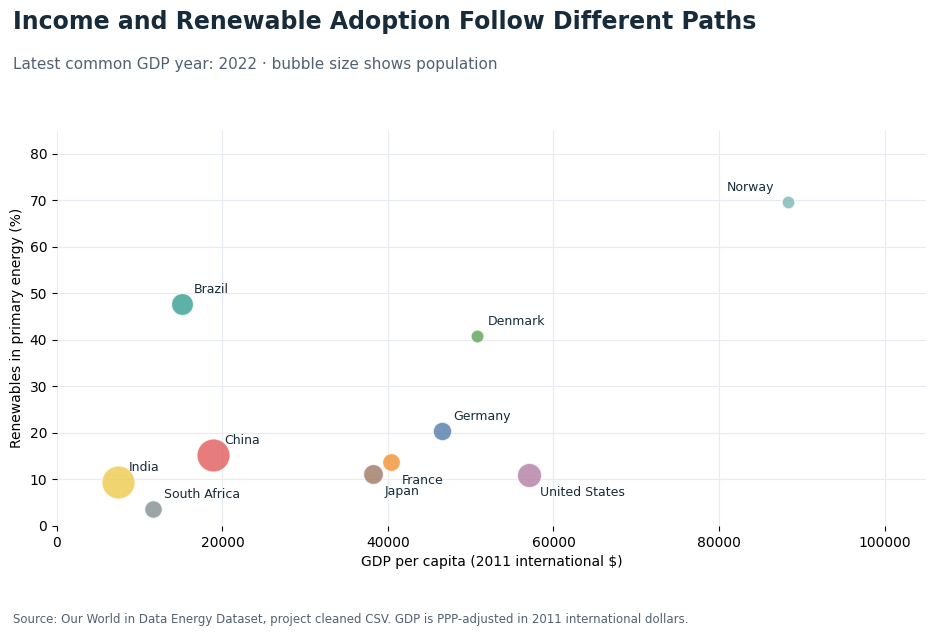

In [6]:
# Static snapshot of the latest common GDP year.
current = v8.loc[v8.year.eq(v8_latest)]
fig, ax = plt.subplots(figsize=(11, 6.7), facecolor="white")
fig.subplots_adjust(left=0.11, right=0.90, top=0.78, bottom=0.19)
offsets = {"Norway": (-10, 8), "Brazil": (8, 8), "Denmark": (8, 8),
           "Germany": (8, 8), "France": (8, -16), "Japan": (8, -15),
           "China": (8, 8), "United States": (8, -15),
           "India": (8, 8), "South Africa": (8, 8)}
for row in current.itertuples():
    ax.scatter(row.gdp_per_capita, row.renewables_share_energy,
               s=55 + 520 * (row.population / current.population.max()) ** 0.5,
               color=country_colors[row.country], alpha=0.78, edgecolor="white", linewidth=1)
    ax.annotate(row.country, (row.gdp_per_capita, row.renewables_share_energy),
                xytext=offsets[row.country], textcoords="offset points", fontsize=9, color="#172B3A",
                ha="right" if offsets[row.country][0] < 0 else "left")
ax.set(xlim=(0, 105000), ylim=(0, 85), xlabel="GDP per capita (2011 international $)",
       ylabel="Renewables in primary energy (%)")
ax.grid(color="#E5EBF0", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.07, 0.96, "Income and Renewable Adoption Follow Different Paths",
         fontsize=17, fontweight="bold", color="#172B3A", va="top")
fig.text(0.07, 0.89, f"Latest common GDP year: {v8_latest} · bubble size shows population",
         fontsize=11, color="#526171", va="top")
fig.text(0.07, 0.045, "Source: Our World in Data Energy Dataset, project cleaned CSV. GDP is PPP-adjusted in 2011 international dollars.",
         fontsize=8.5, color="#526171")
fig.savefig(root / "visuals/08_income_vs_renewables_over_time.png", dpi=250, facecolor="white")
plt.show()

**Visual 8 interpretation.** The benchmark years show varied paths: in 2022, Norway and Brazil had much higher renewable primary-energy shares than several countries at similar or higher GDP per capita. Bubble size adds population context. The scatter describes co-occurrence, not a causal relationship between income and adoption.

### Visual 9 — Renewable share versus renewable volume

Renewable electricity generation is calculated from total electricity generation (TWh) multiplied by the reported renewable electricity share divided by 100. This includes renewable sources beyond the three shown in Visual 5.

In [7]:
volume_cols = ["renewables_share_elec", "electricity_generation"]
volume_valid = data.dropna(subset=volume_cols)
v9_year = 2024
assert volume_valid.loc[volume_valid.year.eq(v9_year), "country"].nunique() == len(countries)
v9 = volume_valid.loc[volume_valid.year.eq(v9_year), ["country", *volume_cols]].copy()
v9["renewable_twh"] = v9.electricity_generation * v9.renewables_share_elec / 100
print(f"Visual 9 common year: {v9_year}; generation is measured in TWh.")
display(v9.sort_values("renewable_twh", ascending=False).round(1))

Visual 9 common year: 2024; generation is measured in TWh.


,country,renewables_share_elec,electricity_generation,renewable_twh
50,China,33.7,10086.9,3398.9
258,United States,24.1,4391.0,1056.6
24,Brazil,87.3,745.7,651.3
154,India,19.8,2036.5,403.4
128,Germany,58.6,496.0,290.9
180,Japan,22.9,1016.4,233.1
206,Norway,98.6,157.1,154.9
102,France,27.2,561.8,152.7
76,Denmark,89.2,35.1,31.3
232,South Africa,12.5,247.5,31.0


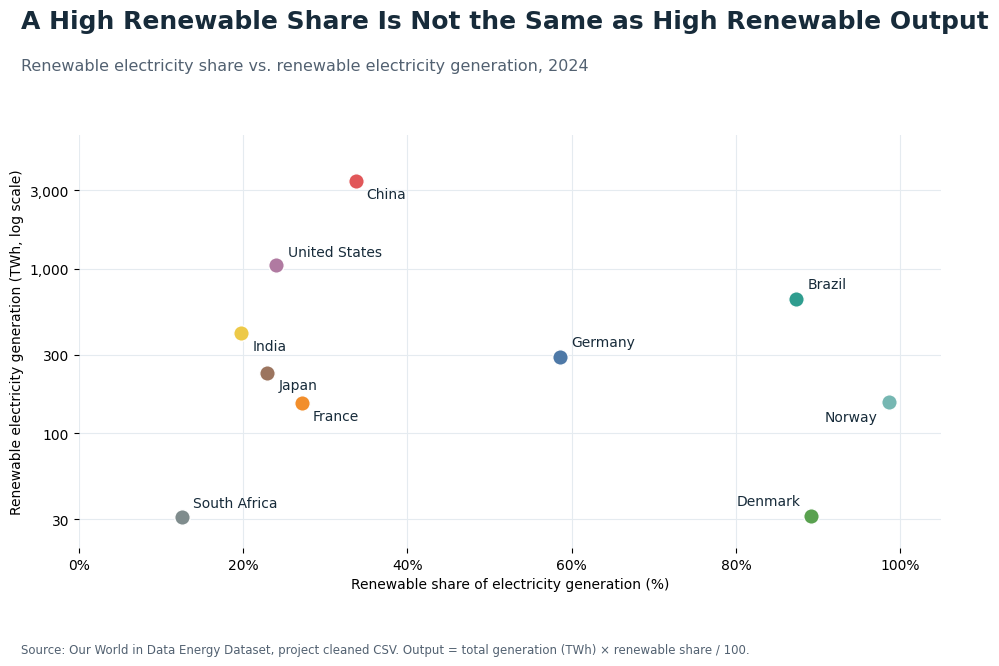

In [8]:
fig, ax = plt.subplots(figsize=(11.5, 7), facecolor="white")
fig.subplots_adjust(left=0.12, right=0.87, top=0.78, bottom=0.19)
offsets = {"China": (8, -12), "United States": (8, 6), "Brazil": (8, 8),
           "India": (8, -12), "Germany": (8, 8), "Japan": (8, -12),
           "Norway": (-8, -14), "France": (8, -12),
           "South Africa": (8, 7), "Denmark": (-8, 8)}
for row in v9.itertuples():
    ax.scatter(row.renewables_share_elec, row.renewable_twh, s=125,
               color=country_colors[row.country], edgecolor="white", linewidth=1, zorder=3)
    ax.annotate(row.country, (row.renewables_share_elec, row.renewable_twh),
                xytext=offsets[row.country], textcoords="offset points", fontsize=10, color="#172B3A",
                ha="right" if offsets[row.country][0] < 0 else "left")
ax.set_yscale("log")
ax.set(xlim=(0, 105), ylim=(20, 6500), xlabel="Renewable share of electricity generation (%)",
       ylabel="Renewable electricity generation (TWh, log scale)")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_yticks([30, 100, 300, 1000, 3000], ["30", "100", "300", "1,000", "3,000"])
ax.minorticks_off()
ax.grid(color="#E5EBF0", linewidth=0.8, which="major")
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.07, 0.96, "A High Renewable Share Is Not the Same as High Renewable Output",
         fontsize=18, fontweight="bold", color="#172B3A", va="top")
fig.text(0.07, 0.89, f"Renewable electricity share vs. renewable electricity generation, {v9_year}",
         fontsize=11.5, color="#526171", va="top")
fig.text(0.07, 0.04,
         "Source: Our World in Data Energy Dataset, project cleaned CSV. Output = total generation (TWh) × renewable share / 100.",
         fontsize=8.5, color="#526171")
fig.savefig(root / "visuals/09_share_vs_volume.png", dpi=250, facecolor="white")
plt.show()

**Q3 takeaway.** In 2024, China produced about 3,399 TWh of renewable electricity with a 33.7% renewable share, while Norway had a 98.6% share and about 155 TWh; Denmark had an 89.2% share and about 31 TWh. Shares and volumes tell different stories because electricity systems differ in size. [Visual 5](../visuals/05_3d_renewable_energy_map.html) adds the geographic and time dimension, but does not encode GDP or electricity volume.

# Final Synthesis

## Visual 5 — Animated 3D renewable-energy map

[Open the interactive map](../visuals/05_3d_renewable_energy_map.html). The existing Plotly implementation below shows hydro, wind, and solar in stacked columns over the Natural Earth world map, with a year slider and Play/Pause for 2000–2024. A [2024 PNG](../visuals/05_3d_renewable_energy_map.png) is only a still image. The three-source column total excludes other renewable electricity sources. European positions are slightly offset for readability.

In [9]:
import json
from pathlib import Path
import pandas as pd

v5_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "data/energy_10countries_clean.csv").is_file()), None)
if v5_root is None:
    raise FileNotFoundError("Run from within the project repository.")

v5_data = pd.read_csv(v5_root / "data/energy_10countries_clean.csv")
v5_geo = json.loads((v5_root / "data/ne_110m_admin_0_countries.geojson").read_text(encoding="utf-8"))

v5_iso = {"Norway": "NOR", "Denmark": "DNK", "Germany": "DEU", "France": "FRA",
          "China": "CHN", "United States": "USA", "India": "IND", "Brazil": "BRA",
          "Japan": "JPN", "South Africa": "ZAF"}
v5_sources = [("hydro_share_elec", "Hydro", "#0072B2"),
              ("wind_share_elec", "Wind", "#009E73"),
              ("solar_share_elec", "Solar", "#E69F00")]   # same colours as Visual 2
v5_cols = [c for c, _, _ in v5_sources]
v5_start, v5_year = 2000, 2024

v5_panel = v5_data.loc[v5_data["country"].isin(v5_iso) & v5_data["year"].between(v5_start, v5_year),
                       ["country", "year", *v5_cols]]
assert set(v5_panel["country"]) == set(v5_iso)
assert not v5_panel.duplicated(["country", "year"]).any()
assert len(v5_panel) == 10 * (v5_year - v5_start + 1), "Missing country-years."
assert v5_panel[v5_cols].notna().all().all(), "Missing source shares."
assert v5_panel[v5_cols].sum(axis=1).le(100.01).all()

# Column positions: each country's Natural Earth label point; three European columns moved apart
v5_label_pt = {f["properties"]["ADM0_A3"]: (f["properties"]["LABEL_X"], f["properties"]["LABEL_Y"])
               for f in v5_geo["features"]}
v5_column_at = {"France": (-11, 45.5), "Denmark": (-3, 57.5), "Germany": (12, 50.5), "Norway": (24, 69.5)}
v5_leaders = ["France", "Denmark", "Norway"]
v5_xy = {c: v5_column_at.get(c, v5_label_pt[v5_iso[c]]) for c in v5_iso}
v5_features = [f for f in v5_geo["features"] if f["properties"]["ADMIN"] != "Antarctica"]

def v5_outer_rings(feature):
    g = feature["geometry"]
    polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    return [poly[0] for poly in polys]

v5_snapshot = (v5_panel.loc[v5_panel["year"].eq(v5_year)].set_index("country")[v5_cols]
               .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False))
display(v5_snapshot.round(1))

# Visual 5 geometry and colours from the reference's static setup.
v5_w, v5_plate = 3.4, 2.5
v5_plate_top, v5_plate_side = "#8FA3B8", "#5B6F84"
v5_years = sorted(v5_panel["year"].unique().tolist())


,hydro_share_elec,wind_share_elec,solar_share_elec,total
country,,,,
Norway,88.8,9.3,0.3,98.5
Brazil,55.4,14.5,9.6,79.5
Denmark,0.1,58.2,10.8,69.1
Germany,4.8,28.5,14.9,48.3
China,13.4,9.9,8.3,31.6
France,12.7,8.1,4.4,25.2
United States,5.4,10.3,6.9,22.6
India,7.7,4.0,7.0,18.7
Japan,7.8,1.1,9.5,18.5


In [10]:
import plotly.graph_objects as go

v5_html = v5_root / "visuals" / "05_3d_renewable_energy_map.html"

def v5_outline_xy(features):
    xs, ys = [], []
    for f in features:
        for ring in v5_outer_rings(f):
            ring = [pt for pt in ring if -135 <= pt[0] <= 165]
            if len(ring) >= 3:
                xs += [pt[0] for pt in ring] + [None]
                ys += [pt[1] for pt in ring] + [None]
    return xs, ys

v5_ox, v5_oy = v5_outline_xy([f for f in v5_features if f["properties"]["ADM0_A3"] not in v5_iso.values()])
v5_fx, v5_fy = v5_outline_xy([f for f in v5_features if f["properties"]["ADM0_A3"] in v5_iso.values()])
def v5_triangulate(ring):
    """Ear-clipping triangulation of a simple polygon ring; returns triangles as index triples."""
    pts = ring[:-1] if ring[0] == ring[-1] else ring[:]
    n = len(pts)
    area = sum(pts[i][0] * pts[(i + 1) % n][1] - pts[(i + 1) % n][0] * pts[i][1] for i in range(n))
    idx = list(range(n)) if area > 0 else list(range(n))[::-1]   # make counter-clockwise
    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    def inside(p, a, b, c):
        return cross(a, b, p) >= 0 and cross(b, c, p) >= 0 and cross(c, a, p) >= 0
    tris, guard = [], 0
    while len(idx) > 3 and guard < 10 * n * n:
        guard += 1
        m = len(idx)
        for k in range(m):
            i0, i1, i2 = idx[k - 1], idx[k], idx[(k + 1) % m]
            a, b, c = pts[i0], pts[i1], pts[i2]
            if cross(a, b, c) <= 0:
                continue
            if any(inside(pts[j], a, b, c) for j in idx if j not in (i0, i1, i2)):
                continue
            tris.append((i0, i1, i2)); idx.pop(k); break
        else:
            break   # no ear found (degenerate ring); stop safely
    if len(idx) == 3:
        tris.append(tuple(idx))
    return pts, tris

# Raised plates for the ten countries: triangulated top faces plus side walls.
# Tops and walls are separate meshes with flat, uniform colour (no lighting artefacts).
v5_plate_mesh = {"top": ([], [], [], [], [], []), "side": ([], [], [], [], [], [])}
def v5_add_tri(part, p0, p1, p2):
    X, Y, Z, I, J, K = v5_plate_mesh[part]
    n = len(X)
    for x, y, z in (p0, p1, p2):
        X.append(x); Y.append(y); Z.append(z)
    I.append(n); J.append(n + 1); K.append(n + 2)
def v5_add_walls(ring):
    for (x0, y0), (x1, y1) in zip(ring[:-1], ring[1:]):
        v5_add_tri("side", (x0, y0, 0), (x1, y1, 0), (x1, y1, v5_plate))
        v5_add_tri("side", (x0, y0, 0), (x1, y1, v5_plate), (x0, y0, v5_plate))
for f in v5_features:
    if f["properties"]["ADM0_A3"] not in v5_iso.values():
        continue
    for ring in v5_outer_rings(f):
        pts, tris = v5_triangulate(ring)
        for a, b, c in tris:
            v5_add_tri("top", (*pts[a], v5_plate), (*pts[b], v5_plate), (*pts[c], v5_plate))
        v5_add_walls(ring)
# Plinths for the two columns moved into the sea, so every column starts at plate height
for c in ["France", "Denmark"]:
    x, y = v5_xy[c]; r = v5_w * 0.8
    sq = [(x - r, y - r), (x + r, y - r), (x + r, y + r), (x - r, y + r), (x - r, y - r)]
    v5_add_tri("top", (*sq[0], v5_plate), (*sq[1], v5_plate), (*sq[2], v5_plate))
    v5_add_tri("top", (*sq[0], v5_plate), (*sq[2], v5_plate), (*sq[3], v5_plate))
    v5_add_walls(sq)
v5_flat = dict(ambient=1.0, diffuse=0.0, specular=0.0, fresnel=0.0)
v5_plate_traces = [
    go.Mesh3d(x=X, y=Y, z=Z, i=I, j=J, k=K, color=color, lighting=v5_flat, hoverinfo="skip",
              name="Selected countries", showlegend=False)
    for part, color in [("side", v5_plate_side), ("top", v5_plate_top)]
    for X, Y, Z, I, J, K in [v5_plate_mesh[part]]
]

v5_lx, v5_ly = [], []
for c in v5_leaders:
    (tx, ty), (cx, cy) = v5_label_pt[v5_iso[c]], v5_xy[c]
    v5_lx += [tx, cx, None]; v5_ly += [ty, cy, None]
v5_map = [
    go.Scatter3d(x=v5_ox, y=v5_oy, z=[0] * len(v5_ox), mode="lines",
                 line=dict(color="#DDE3EA", width=1.2), hoverinfo="skip", showlegend=False),
    *v5_plate_traces,
    go.Scatter3d(x=v5_fx, y=v5_fy, z=[v5_plate + 0.05 if v is not None else None for v in v5_fx],
                 mode="lines", line=dict(color="white", width=1.5), hoverinfo="skip", showlegend=False),
    go.Scatter3d(x=v5_lx, y=v5_ly, z=[v5_plate if v is not None else None for v in v5_lx], mode="lines",
                 line=dict(color="#334155", width=2.5), hoverinfo="skip", showlegend=False),
]

# Triangles for one cuboid (8 corners: 0-3 bottom, 4-7 top)
v5_I = [0, 0, 4, 4, 0, 0, 1, 1, 0, 0, 3, 3]
v5_J = [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6]
v5_K = [2, 3, 6, 7, 5, 4, 6, 5, 7, 4, 6, 7]

# Pixel offsets for label cards that would otherwise overlap (default view)
v5_card_offset = {"United States": (-70, -40), "Brazil": (60, -40), "Germany": (140, -25),
                  "India": (-80, -30), "France": (-60, -30)}

def v5_year_traces(year):
    row = v5_panel.loc[v5_panel["year"].eq(year)].set_index("country")
    base = {c: 0.0 for c in v5_iso}
    details = {
        c: (f"<b>{c} · {year}</b><br>"
            f"Hydro: {float(row.loc[c, 'hydro_share_elec']):.1f}%<br>"
            f"Wind: {float(row.loc[c, 'wind_share_elec']):.1f}%<br>"
            f"Solar: {float(row.loc[c, 'solar_share_elec']):.1f}%<br>"
            f"Three-source total: {float(row.loc[c, v5_cols].sum()):.1f}%")
        for c in v5_iso
    }
    meshes = []
    for col, label, color in v5_sources:
        X, Y, Z, ii, jj, kk, txt = [], [], [], [], [], [], []
        for n, c in enumerate(v5_iso):
            x, y = v5_xy[c]; z0 = v5_plate + base[c]; h = float(row.loc[c, col]); z1 = z0 + h
            w = v5_w / 2 if h >= 0.05 else 0.0   # collapse near-zero segments so no empty cap is drawn
            X += [x - w, x + w, x + w, x - w] * 2
            Y += [y - w, y - w, y + w, y + w] * 2
            Z += [z0] * 4 + [z1] * 4
            ii += [v + 8 * n for v in v5_I]; jj += [v + 8 * n for v in v5_J]; kk += [v + 8 * n for v in v5_K]
            txt += [details[c]] * 8
            base[c] = z1 - v5_plate
        meshes.append(go.Mesh3d(x=X, y=Y, z=Z, i=ii, j=jj, k=kk, color=color, name=label,
                                flatshading=True, text=txt, hovertemplate="%{text}<extra></extra>",
                                lighting=dict(ambient=0.75, diffuse=0.6, specular=0.05), showlegend=True))
    # Scene annotations stay sharp during animation (3D text traces can shrink after a frame change)
    def pct(v):
        return "<1%" if 0 < v < 0.5 else f"{v:.0f}%"
    labels = []
    for c in v5_iso:
        parts = "  ".join(f"<span style='color:{color}'>\u25A0</span> {pct(float(row.loc[c, col]))}"
                          for col, _, color in v5_sources)
        total = base[c]
        total_txt = f"{total:.0f}%" if total >= 1 else f"{total:.1f}%"
        card = dict(x=v5_xy[c][0], y=v5_xy[c][1], z=total + v5_plate,
                    text=f"<b>{c}  {total_txt}</b><br>{parts}", font=dict(size=11, color="#172B3A"),
                    bgcolor="rgba(255,255,255,0.92)", bordercolor="#CBD5E1", borderwidth=1, borderpad=3)
        if c in v5_card_offset:   # moved sideways to avoid overlaps, with a thin pointer line
            ax_, ay_ = v5_card_offset[c]
            card.update(showarrow=True, arrowhead=0, arrowwidth=1, arrowcolor="#94A3B8", ax=ax_, ay=ay_)
        else:
            card.update(showarrow=False, yshift=30)
        labels.append(card)
    return meshes, labels

v5_meshes, v5_labels = v5_year_traces(v5_year)
v5_ifig = go.Figure(data=v5_map + v5_meshes)
v5_frames = []
for y in v5_years:
    meshes, labels = v5_year_traces(y)
    v5_frames.append(go.Frame(name=str(y), data=meshes,
                              traces=list(range(len(v5_map), len(v5_map) + 3)),
                              layout=dict(scene=dict(annotations=labels))))
v5_ifig.frames = v5_frames
v5_steps = [dict(method="animate", label=str(y),
                 args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
            for y in v5_years]
v5_ifig.update_layout(
    title=dict(text="<b>Ten Countries, Ten Different Renewable Pathways</b><br>"
                    "<span style='font-size:14px;color:#526171'>Share of each country's electricity generated from hydro, wind "
                    "and solar. Drag to rotate, scroll to zoom, use the slider to change the year.</span>",
               x=0.03, font=dict(size=22, color="#172B3A")),
    font=dict(family="DejaVu Sans, Arial, sans-serif", color="#172B3A", size=13),
    paper_bgcolor="white", width=1400, height=820, margin=dict(l=20, r=20, t=90, b=120),
    legend=dict(orientation="h", x=0.03, y=0.9, title_text="", font=dict(size=14)),
    scene=dict(xaxis=dict(visible=False, range=[-135, 165]), yaxis=dict(visible=False, range=[-55, 82]),
               zaxis=dict(visible=False, range=[0, 108]),
               aspectmode="manual", aspectratio=dict(x=3.9, y=1.8, z=1.1),
               camera=dict(eye=dict(x=0.3, y=-1.1, z=0.82), center=dict(x=0, y=0, z=0.06),
                           projection=dict(type="orthographic")),
               bgcolor="white", annotations=v5_labels),
    sliders=[dict(active=v5_years.index(v5_year), steps=v5_steps, x=0.12, len=0.85, y=0.02,
                  currentvalue=dict(prefix="Year: ", font=dict(size=14)))],
    updatemenus=[dict(type="buttons", x=0.03, y=0.02, xanchor="left", yanchor="bottom",
                      buttons=[
                          dict(label="▶ Play", method="animate",
                               args=[None, dict(frame=dict(duration=450, redraw=True),
                                                fromcurrent=False, transition=dict(duration=0))]),
                          dict(label="Pause", method="animate",
                               args=[[None], dict(frame=dict(duration=0, redraw=False),
                                                  mode="immediate")])])],
    annotations=[
        dict(text="Source: Our World in Data Energy Dataset; project cleaned CSV. Map: Natural Earth. "
                  "Other renewables (e.g. bioenergy) excluded. Values are rounded, so parts may not add up exactly.",
             x=0.03, y=-0.10, xref="paper", yref="paper", showarrow=False,
             font=dict(size=11, color="#526171"), xanchor="left"),
        dict(text="<b>How to read this map</b><br>Each column shows how much of a country's<br>"
                  "electricity comes from hydro, wind and solar.<br>Taller column = more of these three sources.<br><br>"
                  "Example: Norway 98% means 98 of every 100<br>units of its electricity come from them.",
             x=0.02, y=0.12, xref="paper", yref="paper", xanchor="left", yanchor="bottom", align="left",
             showarrow=False, font=dict(size=11, color="#334155"),
             bgcolor="#F8FAFC", bordercolor="#CBD5E1", borderwidth=1, borderpad=8)],
)
if not v5_html.exists():
    v5_ifig.write_html(v5_html, include_plotlyjs=True, auto_play=False,
                       config={"scrollZoom": True})
    print(f"Saved: {v5_html.relative_to(v5_root)}")
else:
    print(f"Using existing: {v5_html.relative_to(v5_root)}")
v5_ifig.show()


Using existing: visuals\05_3d_renewable_energy_map.html


In [11]:
# Keep the existing 2024 snapshot; create it only when absent.
v5_png = v5_root / "visuals" / "05_3d_renewable_energy_map.png"
if v5_png.exists():
    print(f"Using existing: {v5_png.relative_to(v5_root)}")
else:
    try:
        still = go.Figure(data=list(v5_ifig.data), layout=v5_ifig.layout)
        still.layout.sliders = ()
        still.layout.updatemenus = ()
        still.write_image(v5_png, scale=2)
        print(f"Saved: {v5_png.relative_to(v5_root)} (2024 snapshot)")
    except (ImportError, RuntimeError, ValueError) as exc:
        print(f"2024 PNG export unavailable: {exc}")

Using existing: visuals\05_3d_renewable_energy_map.png


**Conclusion.** Visual 5 combines geography, country differences, renewable source mix, and change over time in one interactive landscape. Visuals 1–4 and 6–9 remain the clearer views for the individual project questions. The map's towers show hydro + wind + solar shares of electricity generation, not the primary-energy share or renewable output in TWh.